In [ ]:
%%html
<center><marquee style='width: 60%; color: blue;'><b>✌ ¡Hola a todos! Un saludo... Vamos a Empezar ✌ </b></marquee><center>

<table>
    <tr>
        <td><img src="https://raw.githubusercontent.com/Fabian830348/Bases_Datos/refs/heads/master/logo_ECI.png" width="300"/></td>
        <td>&nbsp;</td>
        <td>
            <h1 style="font-size:200%;color:blue;text-align:center">    <FONT COLOR="blue">  Clustering  </p> k-means     </h1></td>         
        <td>
            <tp><p style="font-size:99%;text-align:center">Ciencia de Datos</p></tp>
            <tp><p style="font-size:115%;text-align:center">Diplomado 2026-2</p></tp>
            <tp><p style="font-size:115%;text-align:center">Prof. Fabián Sánchez</p></tp>
        </td>
    </tr>
</table>

**Objetivo de la sesión**:

En esta sesión revisaremos el método de k-means y lo aplicaremos a la agrupación o clustering.

Inicialmente, daremos los conceptos básicos del método y un ejemplo general. Luego, aplicaremos el método a un caso de estudio.


# <FONT SIZE=5 COLOR="purple"> 1. Algoritmo k-means </FONT>

**Generalidades**

Tomado de [Joaquin](https://rpubs.com/Joaquin_AR/310338) y de [Sklearn](https://scikit-learn.org/stable/modules/generated/sklearn.cluster.KMeans.html)

- La base de $k$-means fue propuesta por *Stuart Lloyd* en 1957 para la modulación por impulsos codificados. Luego evolucionó con la idea de *Hugo Steinhaus*.

- El término $k$-means clustering fue utilizado por primera vez por *MacQueen en 1967*, es uno de los algoritmos de agrupamiento más simples y más utilizados.

- Es uno de los métodos no supervisados que se usa para dividir un conjunto de individuos (registros del Conjunto de Datos) en un conjunto de $k$ grupos (es decir, ***$k$ clusters***), donde $k$ representa el número de grupos preestablecidos. Este algoritmo busca que los objetos ***dentro del mismo cluster*** sean lo más similares posibles (es decir, alta similitud intraclase), mientras que ***distintos clusteres*** sean lo más diferente posible (es decir, baja similitud entre clases).

- En el $k$-means clustering, cada grupo está representado por su centro (es decir, ***centroide***) que corresponde a la media de puntos asignados al ***cluster***.

- $k$-means clustering encuentra los $k$ mejores clústeres, entendiendo como mejor clúster aquel cuya varianza interna (within-cluster variation) sea lo más pequeña posible.

- Se trata por lo tanto de un problema de optimización, en el que se reparten las observaciones en $k$ clusters de forma que la suma de las varianzas internas de todos ellos sea lo menor posible. Para poder solucionar este problema es necesario definir un modo de cuantificar la varianza interna, que veremos más adelante.

<br>
<center><img src="https://miro.medium.com/v2/resize:fit:1400/format:webp/1*JsfEdbXKwJw_Euprvx17KA.png?raw=true" alt="centered image" width="500" height="300"></center> <center><figcaption> <FONT SIZE=1 COLOR="black"> Fuente: https://miro.medium.com  </FONT> <figcaption></center>
<br>

**Pasos del Algoritmo de k-means**

1. El primer paso es fijar el número $k$  de clusters que se desean obtener.

2. El algoritmo comienza seleccionando aleatoriamente $k$ puntos del conjunto de datos para que sirvan como centroides iniciales de los cluster.

3. Cada punto del conjunto de datos se asigna al cluster cuyo centroide esté más cercano. Esto se hace usualmente con la distancia euclideana. Es decir, que si $\{\mu_1^{1}, \mu_2^{1}, \dots, \mu_k^{1}\}$ son los centroides iniciale, el punto $x_i$ se asigna al cluster cuyo centroide minimiza

$$ \|x_i-\mu_j^{1} \| \quad 1 \leq j \leq k\}$$

En otras palabras

$$Cluster(x_i) = argmin_j  \|x_i-\mu_j^{1} \|$$

Este proceso se repite para todos lo puntos del conjunto.

Cuando se identifica el centroide más cercano, el punto $x_i$ se asigna al cluster correspondiente a ese centroide.

4. Ahora, vamos a actualizar los centroides. El nuevo centroide se actualiza mediante la media aritmética de los puntos asociados al cluster. Es decir,

$$\mu_i^{2}= \dfrac{1}{|C_{i}^{2}|}\sum \limits_{x_j \in C_i^{2}} x_j$$

y en general,

$$\mu_i^{t+1}= \dfrac{1}{|C_{i}^{t}|}\sum \limits_{x_j \in C_i^{t}} x_j$$

donde $C_i^{t}$ es el cluster $i$ en la iteración $t$ y $|C_{i}^{t}|$ es el número de elementos de ese cluster.

Aca nos preguntamos, ¿cuando debemos parar?

5. En este punto vamos a tratar la función objetivo del algoritmo.

Tenemos que $\{C_1,C_2, \dots, C_k\}$, $k$ conjuntos que contienen las observaciones del conjunto de datos, tales que:

- $C_1 \cup C_2 \cup \dots \cup C_k = {1,2,3, \dots, k}$. Cada observación pertence a uno de los $k$ clusters.

- $C_i \cap C_j = \emptyset $, para $i \neq j$. Es decir, que un registro no puede estar en diferentes clusters.

El objetivo de k-means es consiste en definir grupos de modo que el total de la variación **intra-cluster** sea mínima. A esta cantidad se le conoce como: ***inertia*** o  **within-cluster sum-of-squares** y está definida mediante:

$$WCSS =\sum_{n=1}^{k} W(C_n)= \sum_{n=1}^{k} \sum_{x_i \in C_{n}}||x_i -\mu_n||^2$$

donde,

 - $W(C_k) = \sum_{x_i \in C_{k}}||x_i -\mu_k||^2$

 - $x_i$ es un registro que pertence al cluster $C_k$.

 - $\mu_k$ es el valor promedio de los registros asignados al cluster $C_k$

El algoritmo $k$-means tiene como objetivo elegir ***centroides*** que minimicen la ***inercia***. Esto mide la compacidad del agrupamiento y se quiere que sea lo mas baja posible.

Finalmente, podemos formular el problema mediante:

$$ \min  E(\mu_i)  = \min \sum \limits_{i=1}^{k} \sum \limits_{x_i \in C_n} \|x_i -\mu_n \|^2$$

donde $C$ es el conjunto de datos cuyos elementos son los objetos $x_i$ representados por vectores y cada uno de sus elementos representa una característica o atributo. Tenemos $k$ clusters o grupos con su correspondiente centroide $\mu_n$.

En cada actualización de los centroides, desde el punto de vista matemático, debemos poner una condición necesaria de extremo a la función $E(\mu_i)$

$$\dfrac{\partial E}{\partial \mu_n}=0$$

se puede demostrar que:

$$\mu_i^{(t+1)} = \dfrac{1}{|C_i^{(t)}|} \sum \limits_{x_j \in C_i^{(t)}}x_j$$.





# <FONT SIZE=5 COLOR="purple"> 2. Ejemplo de la idea general </FONT>

Primero, vamos a cargar las librerías.

In [3]:
# librerías para procesar
import numpy  as np
import pandas as pd

# librerías para graficar
import matplotlib.pyplot as plt
import seaborn           as sns
import plotly.express    as px

# Algunos elementos de preprocesamiento: escalamiento y selección de k en k-means
from sklearn.preprocessing     import StandardScaler
from sklearn.metrics           import silhouette_samples, silhouette_score

# Para el algoritmo k-means
from sklearn.cluster           import KMeans

# Para otros algoritmos de machine learning
from sklearn.decomposition     import PCA
from sklearn.neighbors         import KNeighborsClassifier
from sklearn.neighbors         import NearestNeighbors
from sklearn.metrics           import pairwise_distances_argmin_min

#Para omitir los warnings
import warnings
warnings.filterwarnings("ignore")

El siguiente código genera un gráfico interactivo que permite mover el número de clusters.

In [ ]:
# @title
import numpy as np
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans
import ipywidgets as widgets
from ipywidgets import interact

# Datos de ejemplo para clustering
np.random.seed(7)
x1 = np.random.standard_normal((100,2))*0.6+np.ones((100,2))
x2 = np.random.standard_normal((100,2))*0.5-np.ones((100,2))
x3 = np.random.standard_normal((100,2))*0.4-2*np.ones((100,2))+5
X = np.concatenate((x1,x2,x3),axis=0)

# Función para actualizar el gráfico de clustering según el valor de n
def actualizar_cluster(n):
    # Crear y ajustar el modelo K-means
    k_means = KMeans(n_clusters=n, random_state=0)
    k_means.fit(X)

    # Obtener centroides y etiquetas
    centroides = k_means.cluster_centers_
    etiquetas = k_means.labels_

    # Graficar los clusters
    plt.figure(figsize=(8, 6))
    colores = ['r', 'b', 'g', 'c', 'm', 'y', 'k']  # Diferentes colores para cada cluster
    for i in range(n):
        plt.plot(X[etiquetas == i, 0], X[etiquetas == i, 1], colores[i % len(colores)] + '.', label=f'Cluster {i+1}')

    # Graficar los centroides
    plt.plot(centroides[:, 0], centroides[:, 1], 'mo', markersize=10, label='Centroides')
    plt.title(f'Número de clusters: {n}\nInercia: {round(k_means.inertia_, 2)}')
    plt.legend(loc='best')
    plt.xlabel('Eje X')
    plt.ylabel('Eje Y')
    plt.show()

# Crear el control deslizante para el número de clusters
u = interact(actualizar_cluster, n=widgets.IntSlider(value=3, min=1, max=10, step=1, description='Clusters'))


In [ ]:
!pip install imageio

Vamos a ilustrar como el método selecciona los centroides dependiendo del número del clústers

# <FONT SIZE=5 COLOR="purple"> 3. ¿Cuántos clúster debemos seleccionar? </FONT>


- Determinar el número óptimo de clusters en un conjunto de datos es un problema fundamental en el agrupamiento. En $k$-means se requiere especificar de antemano el número de clusters $k$ que se generarán.

- Desafortunadamente no hay una respuesta definitiva a esta pregunta. El número óptimo de clusters es algo subjetivo y depende del método utilizado para medir
similitudes y los parámetros utilizados para la partición.

Vamos a describir dos métodos para determinar el número óptimo de clusters para $k$-means: ***elbow method*** y ***silhouette***





## <FONT SIZE=4 COLOR="green"> 3.1 El método del codo </FONT>

La idea básica detrás del método $k$-means, es definir el número de clusters que minimizan la inercia ***WCSS***. Recordemos que ***WCSS*** mide la compacidad del agrupamiento y queremos que sea lo más pequeño posible.

El **método codo** analiza el ***WCSS*** como una función del número de clusters. Se debe elegir una cantidad de clusters de tal forma que agregar otro cluster no mejore, en gran medida, el valor ***WCSS***.

El número óptimo de clusters se puede definir de la siguiente manera:

1. Calcule el algoritmo de clustering $k$-means para diferentes valores de $k$. Por ejemplo, puede variar $k$ de 1 a 10 grupos.

2. Para cada $k$, calcule ***WCSS***.

3. Trazar la curva de ***WCSS*** según el número de clusters $k$.

4. La ubicación de una curva (codo) en el plot generalmente se considera como un indicador del número adecuado de clusters.

Tenga en cuenta que el método del codo a veces es ambigüo.

El método del codo utiliza la inercia (WCSS), definida como la suma de las distancias euclidianas al cuadrado entre cada observación y el centroide del clúster al que pertenece. A medida que aumenta K, la inercia disminuye o se mantiene. Se busca identificar el punto a partir del cual agregar nuevos clústeres produce una reducción relativamente pequeña de la inercia.

$$WCSS=\sum_{j=1}^{K}\sum_{x_i\in C_j}\|x_i-\mu_j\|^2 $$

No se debe seleccionar simplemente el $k$ que tenga la menor inercia, porque aumentar el número de grupos tiende a reducirla. Buscamos el cambio de pendiente.


[ver](https://machinelearningparatodos.com/segmentacion-utilizando-k-means-en-python/)


<center><img src="https://github.com/Fabian830348/cursos/blob/a78eef65f7afa2e9096475bf1860843870f52276/Imagen/elbow.png?raw=true" alt="centered image" width="400" height="250"></center>

El punto en el que se observa ese cambio brusco en la inercia nos dirá el número óptimo de clusters a seleccionar para ese conjunto de datos; o dicho de otra manera: el punto que representaría al codo del brazo será el número óptimo de clusters para ese conjunto.

"within= [] ## Elbow Graph (codo), se tiende a elegir muchos grupos
for k in range(1,10):
    kmeanModel = KMeans(n_clusters=k).fit(nuevosACP)
    within.append(kmeanModel.inertia_)
fig=px.line(x=list(range(1,10)), y=within)
fig.show()


## <FONT SIZE=4 COLOR="green"> 3.2 El método de la Silueta </FONT>

- El coeficiente de silueta mide qué tan bien se agrupa una observación y estima la ***distancia promedio entre clusters***.

- El gráfico de la silueta muestra una medida de qué tan cerca está cada punto en un cluster de los puntos en los clusters vecinos.

Para cada observación $i$, el ancho de la silueta $s_i$ se calcula de la siguiente manera:

1. Para cada observación $i$, calculamos la disimilitud (distancia) promedio $a_i$, entre $i$ y todos los otros puntos del cluster al que pertenezca $i$.

$$a_i = \dfrac{1}{|C_i|-1} \sum \limits_{j \in C_i , i\neq j} d(i,j)$$

esto es, la distancia media entre $i$ y los otros puntos del mismo clúster. *¿Por qué se divide por esa expresión?*

2. Para todos los demás clusters $C$, a los que no pertenezca $i$, calcule el promedio de disimilitud $d(i,C)$ de $i$ con todos los puntos de $C$. La menor de estas $d(i,C)$ se define como $b_i = min_C\  d(i,C)$. El valor de $b_i$ puede verse como la disimilitud promedio entre $i$ y su cluster "vecino", es decir, el más cercano al que ***no*** pertenece.

$$b_i = \min \limits_{k \neq i}\dfrac{1}{|C_k|} \sum \limits_{j \in C_k} d(i,j)$$

3. Finalmente, el ancho de la silueta de la observación $i$ se define mediante la fórmula:

$$S_i = \frac{(b_i - a_i)}{max\{a_i, b_i\}}$$

El ancho de la silueta se puede interpretar de la siguiente manera:

- Primero, este valor está entre $-1$ y $1$.

- Las observaciones con un $S_i$ cercano a 1 están muy bien agrupadas.

- Un $S_i$ pequeño (alrededor de 0) significa que la observación se encuentra entre dos grupos.

- Las observaciones con un $S_i$ negativo probablemente estén ubicadas en el cluster incorrecto.

El algoritmo es similar al método del codo y se puede calcular de la siguiente manera:

1. Calcule el algoritmo $k$-means  para diferentes valores de $k$. Por ejemplo, variando $k$ de 1 a 10 grupos.

2. Para cada $k$, calcule la silueta promedio de las observaciones.

3. Trazar el gráfico según el número de clusters y la silueta promedio.

4. La ubicación del máximo se considera como el número apropiado de clusters.

# <FONT SIZE=5 COLOR="purple"> 4. Ejemplo de k-means </FONT>

Vamos a importar los siguientes datos que contienen información sobre algunos delitos y el tamaño de la población urbana en estados de USA. El objetivo es buscar agrupar los datos que tal manera que los elementos de los cluster tengan información común que los pueda caracterizar.

## <FONT SIZE=4 COLOR="green"> 4.1 Carga y Exploración </FONT>

In [4]:
# Traemos los datos de la url.
USArrests = pd.read_csv("https://raw.githubusercontent.com/Fabian830348/Bases_Datos/refs/heads/master/usarrests.csv", index_col=0)
USArrests.head()

,Murder,Assault,UrbanPop,Rape
Alabama,13.2,236,58,21.2
Alaska,10.0,263,48,44.5
Arizona,8.1,294,80,31.0
Arkansas,8.8,190,50,19.5
California,9.0,276,91,40.6


Primero, hacemos una exploración rápida de los datos

In [5]:
# tamaño de los datos
USArrests.shape

(50, 4)

In [6]:
# información de datos faltantes
USArrests.info()

<class 'pandas.core.frame.DataFrame'>
Index: 50 entries, Alabama to Wyoming
Data columns (total 4 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   Murder    50 non-null     float64
 1   Assault   50 non-null     int64  
 2   UrbanPop  50 non-null     int64  
 3   Rape      50 non-null     float64
dtypes: float64(2), int64(2)
memory usage: 4.0+ KB


No hay datos faltantes. Veamos algunas estadísticas

In [7]:
# estadísticas de los datos
USArrests.describe()

,Murder,Assault,UrbanPop,Rape
count,50.00000,50.000000,50.000000,50.000000
mean,7.78800,170.760000,65.540000,21.232000
std,4.35551,83.337661,14.474763,9.366385
min,0.80000,45.000000,32.000000,7.300000
25%,4.07500,109.000000,54.500000,15.075000
50%,7.25000,159.000000,66.000000,20.100000
75%,11.25000,249.000000,77.750000,26.175000
max,17.40000,337.000000,91.000000,46.000000


In [8]:
USArrests.columns

Index(['Murder', 'Assault', 'UrbanPop', 'Rape'], dtype='object')

In [9]:
for col in USArrests.columns:
  fig = px.box(USArrests[col])
  fig.show()

In [ ]:
import pandas as pd
import plotly.express as px

def boxplots_variables_numericas_plotly(df):
    # Seleccionar solo las columnas numéricas
    df_numerico = df.select_dtypes(include=['number'])

    # Convertir el DataFrame en formato largo para que Plotly pueda graficar
    df_long = df_numerico.melt(var_name='Variable', value_name='Valor')

    # Crear el boxplot con Plotly Express
    fig = px.box(df_long,
                 x='Variable',
                 y='Valor',
                 color='Variable',
                 title='Boxplots de Variables Numéricas')
    fig.update_layout(xaxis_title='Variables', yaxis_title='Valores')
    fig.show()

boxplots_variables_numericas_plotly(USArrests)


In [ ]:
px.histogram(USArrests.Murder)

Es importante escalar los datos ya que estamos trabajando con distancias entre elementos del conjunto de datos.

In [ ]:
USArrests.head()

,Murder,Assault,UrbanPop,Rape
Alabama,13.2,236,58,21.2
Alaska,10.0,263,48,44.5
Arizona,8.1,294,80,31.0
Arkansas,8.8,190,50,19.5
California,9.0,276,91,40.6


In [ ]:
# Escalamos los datos
scaler = StandardScaler()
scaler.fit(USArrests)
df = pd.DataFrame(scaler.transform(USArrests),
                  columns = USArrests.columns,
                  index = USArrests.index)
df.head(6)

,Murder,Assault,UrbanPop,Rape
Alabama,1.255179,0.790787,-0.526195,-0.003451
Alaska,0.513019,1.118060,-1.224067,2.509424
Arizona,0.072361,1.493817,1.009122,1.053466
Arkansas,0.234708,0.233212,-1.084492,-0.186794
California,0.281093,1.275635,1.776781,2.088814
Colorado,0.025976,0.402909,0.869548,1.883901


## <FONT SIZE=4 COLOR="green"> 4.2 Generación del modelo con $k=2$ </FONT>

Inicialmente, aplicaremos el algoritmo *kmeans* con dos clusters.

In [ ]:
# generación del modelo con dos clusters kmeans()
k = 2
kmeans = KMeans(n_clusters=k,                  #Número de clusters
                random_state=0)                #Semilla aleatoria.
kmeans.fit(df)

KMeans(n_clusters=2, random_state=0)

Revisamos los atributos, es decir, la inercia y los centroides de los clústers.

In [ ]:
# Inertia y centroides
print(kmeans.inertia_)
print(kmeans.cluster_centers_)

104.96163315756873
[[ 1.01513667  1.02412028  0.19959126  0.85556386]
 [-0.67675778 -0.68274685 -0.13306084 -0.57037591]]


Los coloco como un DataFrame para visualizarlos mejor

In [ ]:
# Los datos anteriores pero en DataFrame
centroides = pd.DataFrame(kmeans.cluster_centers_, columns = df.columns)
centroides

,Murder,Assault,UrbanPop,Rape
0,1.015137,1.024120,0.199591,0.855564
1,-0.676758,-0.682747,-0.133061,-0.570376


Veamos los labels (etiquetas de grupos) que genera el modelo.

In [ ]:
# Atributos.
print(kmeans.labels_)

[0 0 0 1 0 0 1 1 0 0 1 1 0 1 1 1 1 0 1 0 1 0 1 0 0 1 1 0 1 1 0 0 0 1 1 1 1
 1 1 0 1 0 0 1 1 1 1 1 1 1]


Ponemos está información en el DataFrame con la información del conjunto de datos

In [ ]:
USArrests.head()

,Murder,Assault,UrbanPop,Rape
Alabama,13.2,236,58,21.2
Alaska,10.0,263,48,44.5
Arizona,8.1,294,80,31.0
Arkansas,8.8,190,50,19.5
California,9.0,276,91,40.6


In [ ]:
df_cluster = USArrests.copy()
df_cluster["cluster"] = kmeans.labels_
df_cluster.head(20)

,Murder,Assault,UrbanPop,Rape,cluster
Alabama,13.2,236,58,21.2,0
Alaska,10.0,263,48,44.5,0
Arizona,8.1,294,80,31.0,0
Arkansas,8.8,190,50,19.5,1
California,9.0,276,91,40.6,0
Colorado,7.9,204,78,38.7,0
Connecticut,3.3,110,77,11.1,1
Delaware,5.9,238,72,15.8,1
Florida,15.4,335,80,31.9,0
Georgia,17.4,211,60,25.8,0


In [ ]:
df_cluster[df_cluster.cluster == 1]

,Murder,Assault,UrbanPop,Rape,cluster
Arkansas,8.8,190,50,19.5,1
Connecticut,3.3,110,77,11.1,1
Delaware,5.9,238,72,15.8,1
Hawaii,5.3,46,83,20.2,1
Idaho,2.6,120,54,14.2,1
Indiana,7.2,113,65,21.0,1
Iowa,2.2,56,57,11.3,1
Kansas,6.0,115,66,18.0,1
Kentucky,9.7,109,52,16.3,1
Maine,2.1,83,51,7.8,1


Veamos la media en cada uno de los clusters

In [ ]:
df_cluster.groupby(by = ["cluster"]).mean()

,Murder,Assault,UrbanPop,Rape
cluster,,,,
0,12.165,255.250000,68.400000,29.165000
1,4.870,114.433333,63.633333,15.943333


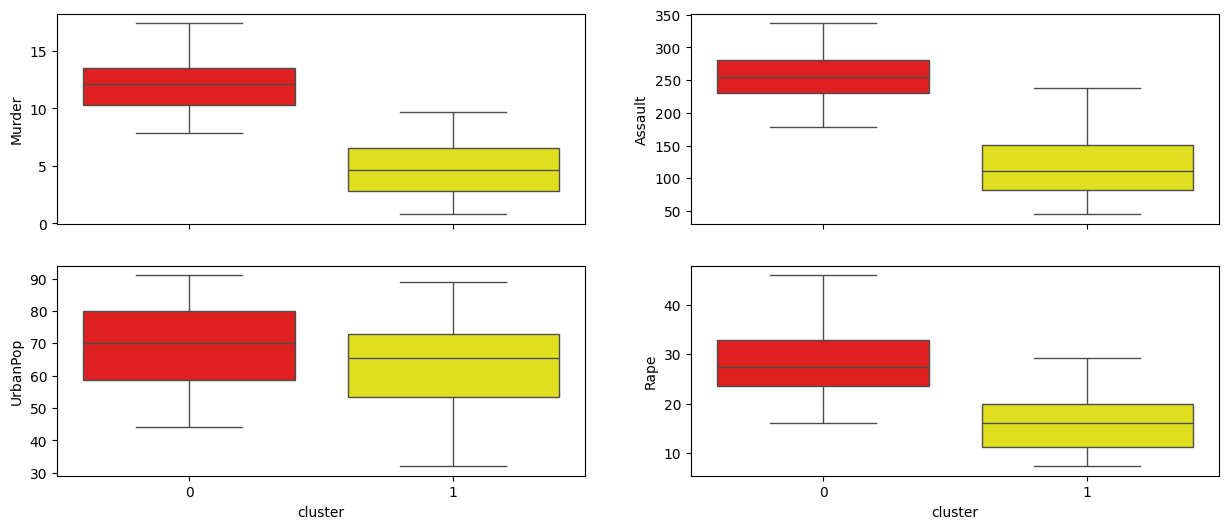

In [ ]:
## Caso 2 clusters
plt.rcParams["figure.figsize"] = (15,6)
df_Clusters2 = USArrests.copy()
df_Clusters2["cluster"] = kmeans.labels_
df_Clusters2["cluster"] = df_Clusters2["cluster"].astype("category")
## Box-plots
fig, axes = plt.subplots(2,2, sharex=True)
## Gráfica
my_colors = {'0': 'red', '1': 'yellow'}
sns.boxplot(data=df_Clusters2, x = "cluster", y = "Murder", palette = my_colors, ax = axes[0,0])
sns.boxplot(data=df_Clusters2, x = "cluster", y = "Assault",  palette = my_colors,ax = axes[0,1])
sns.boxplot(data=df_Clusters2, x = "cluster", y = "UrbanPop", palette = my_colors, ax = axes[1,0])
sns.boxplot(data=df_Clusters2, x = "cluster", y = "Rape", palette = my_colors, ax = axes[1,1])

plt.show()

Vamos a realizar la clasificación de un nuevo registro

In [ ]:
X_nuevo = np.array([[13,	250,	47,	20]])
X_nescalado = scaler.transform(X_nuevo.reshape(1, -1))
new_labels = kmeans.predict(X_nescalado)
print(new_labels)

[1]


In [ ]:
#veamos el representante del grupo, el usuario cercano a su centroide
closest, _ = pairwise_distances_argmin_min(kmeans.cluster_centers_, df)
closest

array([30, 26])

In [ ]:
users=df.index
for row in closest:
    print(users[row])

New Mexico
Nebraska


Para este ejemplo, como tenemos dos clusters podemos hacer una gráfica de la distancia de cada registro al centro del grupo.

In [ ]:
temp = pd.DataFrame(kmeans.transform(df),)
temp["cluster"] = kmeans.predict(df)
temp["cluster"] = temp["cluster"].astype("category")
sns.scatterplot(data = temp,
                x = 0,
                y = 1,
                hue = "cluster")
plt.show()


Además, podemos visualizar, hasta en tres dimensiones, como se comportan los clusters.

In [ ]:
fig = px.scatter_3d(df_cluster, x='Assault', y='UrbanPop', z='Murder', color = "cluster")
fig.show()
fig.write_html("/content/file.html")

Analicemos un poco los grupos. Para esto vamos a realizar los diagramas de cajas

In [ ]:
import plotly.graph_objects as go
from plotly.subplots import make_subplots
from sklearn.cluster import KMeans
# Ejemplo de datos (USArrests) y modelo KMeans
df_Clusters2 = USArrests.copy()
df_Clusters2["cluster"] = kmeans.labels_
df_Clusters2["cluster"] = df_Clusters2["cluster"].astype("category")

# Crear subplots de 2x2
fig = make_subplots(rows=2, cols=2, subplot_titles=['Murder', 'Assault', 'UrbanPop', 'Rape'])

# Boxplot para "Murder"
fig1 = px.box(df_Clusters2,
              x='cluster',
              y='Murder',
              color='cluster')
for trace in fig1.data:
    fig.add_trace(trace, row=1, col=1)

# Boxplot para "Assault"
fig2 = px.box(df_Clusters2,
              x='cluster',
              y='Assault',
              color='cluster')
for trace in fig2.data:
    fig.add_trace(trace, row=1, col=2)

# Boxplot para "UrbanPop"
fig3 = px.box(df_Clusters2,
              x='cluster',
              y='UrbanPop',
              color='cluster')
for trace in fig3.data:
    fig.add_trace(trace, row=2, col=1)

# Boxplot para "Rape"
fig4 = px.box(df_Clusters2,
              x='cluster',
              y='Rape',
              color='cluster')
for trace in fig4.data:
    fig.add_trace(trace, row=2, col=2)

# Actualizar layout
fig.update_layout(
    title_text="Boxplots de Variables por Cluster",
    height=1000,
    width=1000,
    showlegend=False
)

fig.show()


También la podemos hacer en seaborn

In [ ]:
## Caso 2 clusters
plt.rcParams["figure.figsize"] = (15,6)
df_Clusters2 = USArrests.copy()
df_Clusters2["cluster"] = kmeans.labels_
df_Clusters2["cluster"] = df_Clusters2["cluster"].astype("category")
## Box-plots
fig, axes = plt.subplots(2,2, sharex=True)
## Gráfica
my_colors = {'0': 'red', '1': 'yellow'}
sns.boxplot(data=df_Clusters2, x = "cluster", y = "Murder", palette = my_colors, ax = axes[0,0])
sns.boxplot(data=df_Clusters2, x = "cluster", y = "Assault",  palette = my_colors,ax = axes[0,1])
sns.boxplot(data=df_Clusters2, x = "cluster", y = "UrbanPop", palette = my_colors, ax = axes[1,0])
sns.boxplot(data=df_Clusters2, x = "cluster", y = "Rape", palette = my_colors, ax = axes[1,1])

plt.show()

***Comentarios:***

1. El cluster 1 tiene una alta tasa delictiva y predomina la población urbana.

2. El cluster 0 tiene tasas bajas de delitos y una menor tasa que el cluster 1 de población urbana.

Note que la solución en este caso es bastante simple, pues solo está teniendo en consideración las tasas de crimenes altos con "población urbana" y tasa de crimenes bajos con "población rural". Esta solución parece ser buena, pues logra identificar los estados que tienen alto y bajo crimen.

## <FONT SIZE=4 COLOR="green"> 4.3 Selección de $k$ </FONT>

Para la selección del número de clústers $k$ usaremos:

- Método del codo
- Método de la silueta.

Para el método del codo podemos hacer la iteración sobre el número de grupos $k$ y generar la inercia $within$ y luego, representar gráficamente.

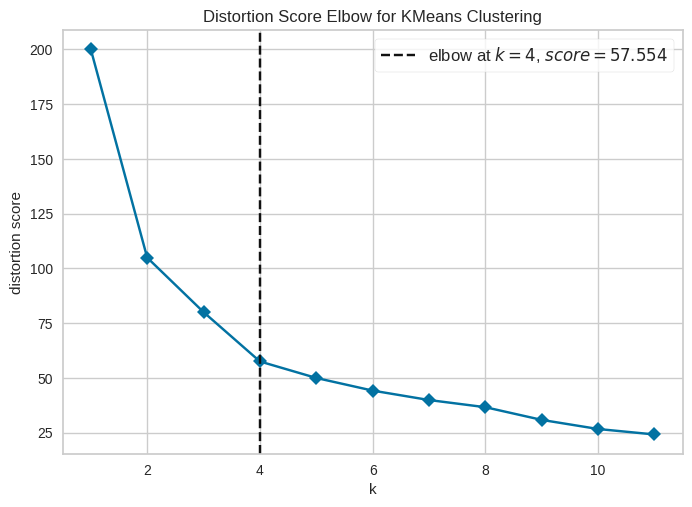

<Axes: title={'center': 'Distortion Score Elbow for KMeans Clustering'}, xlabel='k', ylabel='distortion score'>

In [ ]:
from yellowbrick.cluster import KElbowVisualizer
from sklearn.cluster     import KMeans

model = KMeans(random_state=0,
               n_init=10 )                                # definimos el modelo



visualizer = KElbowVisualizer(model,                      # definimos el visualizador
                              k=(1,12),                   # intervalo de los valores de k
                              metric="distortion",         # la métrica coincide con la inertia
                              timings=False)              # para que no aparezca fit-time
visualizer.fit(df)                                        # Entrenamos con los datos
visualizer.show(show=False)                               # mostramos la gráfica


Según el gráfico anterior podemos usar, por ejemplo, $k=2$ o $k=4$. Sin embargo, el último valor parece más apropiado ya que para los valores siguientes el cambio en la inercia es menor.

Ahora, veamos que nos sugiere el método de la silueta

In [ ]:
# generación de los modelos para diferentes valores de $k$
models = [KMeans(n_clusters=n, random_state=0 ).fit(df) for n in range(2,11)]
silhouette_scores = [silhouette_score(df, model.labels_) for model in models]

# gráficamos los valores de la silueta para cada valor de k
plt.plot(list(range(2, 11)), silhouette_scores, "bo-")
plt.xlabel("Número de clusters $k$", fontsize=14)
plt.ylabel("Silhouette score", fontsize=14)
plt.title("Método de la Silueta")
plt.show()

El método de la silueta permite comparar diferentes valores de $k$ mediante el coeficiente promedio de silueta.

Generalmente, se prefiere un valor de $k$ que produzca una silueta promedio elevada, ya que indica una combinación favorable de cohesión interna y separación entre los clústeres.

En general, se usan de la mano los dos métodos: codo y siluetta.


Ahora, vamos a repetir el ejercicio con $k=4$ clusters.

In [ ]:
k = 4                                 # número de clusters
kmeans_4 = KMeans(n_clusters=k,         # Definir el modelo
                random_state=0)         # Semilla aleatoria.
kmeans_4.fit(df)                        # Entrenar el modelo

KMeans(n_clusters=4, random_state=0)

In [ ]:
# Revisamos los atributos importantes del modelo: inercia y los centroides
print(kmeans_4.inertia_)
print(kmeans_4.cluster_centers_)

58.24158433134323
[[ 0.75759426  1.13128272  0.94567938  1.22798509]
 [-0.44878894 -0.35858791  0.56576856 -0.20455729]
 [-0.97130281 -1.11783581 -0.93954982 -0.97657842]
 [ 1.32475684  0.90930557 -0.86737678  0.29612861]]


Colocaremos la información en un DataFrame y luego haremos las gráficas de los boxplots para hacer el análisis.

In [ ]:
kmeans_4.labels_

array([3, 3, 0, 3, 0, 0, 1, 1, 0, 3, 1, 2, 0, 1, 2, 1, 2, 3, 2, 0, 1, 0,
       2, 3, 1, 2, 2, 0, 2, 1, 0, 0, 3, 2, 1, 1, 1, 1, 1, 3, 2, 3, 0, 1,
       2, 1, 1, 2, 2, 1], dtype=int32)

In [ ]:
#4 Caso 4 clusters
df_Clusters4 = USArrests.copy()
df_Clusters4["cluster"] = kmeans_4.labels_
df_Clusters4.head(10)

,Murder,Assault,UrbanPop,Rape,cluster
Alabama,13.2,236,58,21.2,3
Alaska,10.0,263,48,44.5,3
Arizona,8.1,294,80,31.0,0
Arkansas,8.8,190,50,19.5,3
California,9.0,276,91,40.6,0
Colorado,7.9,204,78,38.7,0
Connecticut,3.3,110,77,11.1,1
Delaware,5.9,238,72,15.8,1
Florida,15.4,335,80,31.9,0
Georgia,17.4,211,60,25.8,3


In [ ]:
# tabla de frecuencias de la variable cluster
df_Clusters4["cluster"].value_counts()

,count
cluster,
1,17
2,13
0,11
3,9


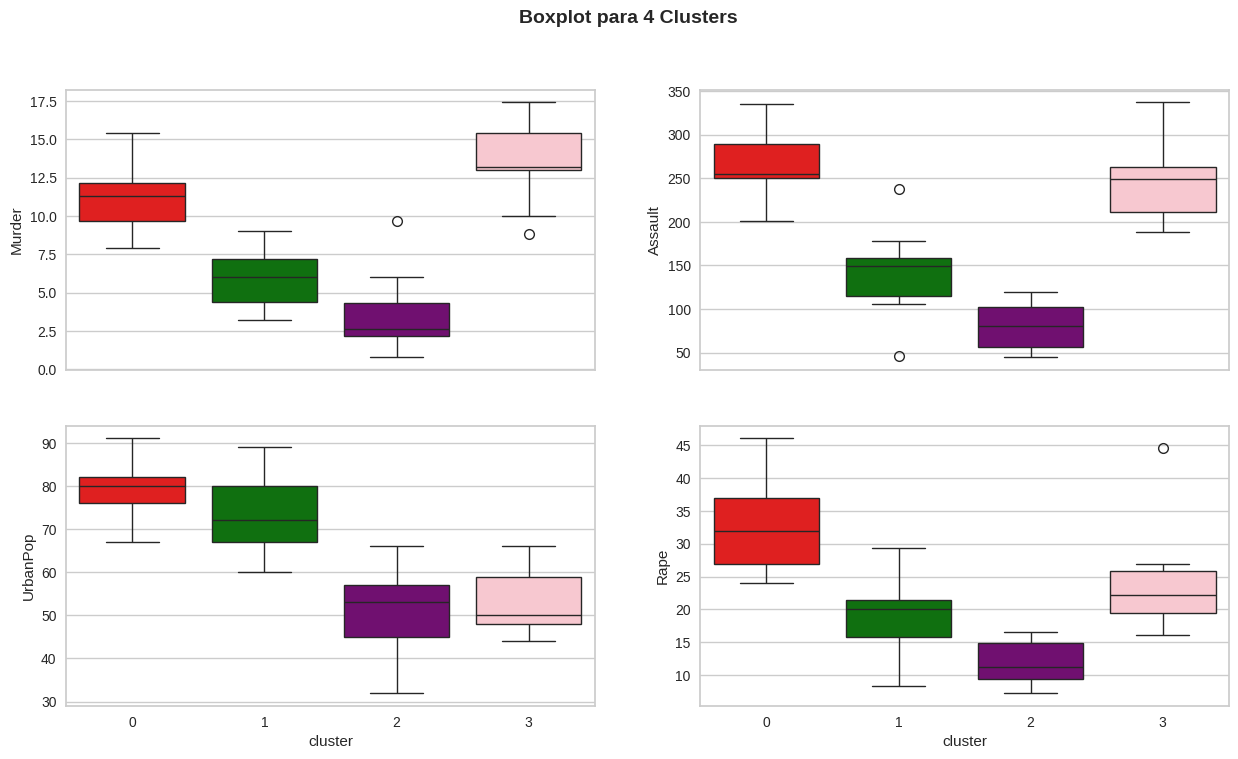

In [ ]:
# Box-plots
plt.rcParams["figure.figsize"] = (15,8)
fig, axes = plt.subplots(2,2, sharex=True)
my_colors2 ={"0": "red" , "1" : "green" , "2" : "purple" , "3" : "pink"}
sns.boxplot(data=df_Clusters4, x = "cluster", y = "Murder",palette = my_colors2, ax = axes[0,0])
sns.boxplot(data=df_Clusters4, x = "cluster", y = "Assault",palette = my_colors2, ax = axes[0,1])
sns.boxplot(data=df_Clusters4, x = "cluster", y = "UrbanPop", palette = my_colors2,ax = axes[1,0])
sns.boxplot(data=df_Clusters4, x = "cluster", y = "Rape", palette = my_colors2,ax = axes[1,1])
fig.suptitle("Boxplot para 4 Clusters", fontsize=14, fontweight="bold",)
plt.show()

***Comentarios:***


1. El cluster 3 tiene alto el índice de asesinatos. El cluster 2 tiene un menor índice de asesinatos.

2. *Assault* y *Murder*  tiene un comportamiento similar para los clusters.

4. Note que el cluster 1 tiene una tasa más alta de asaltos que el cluster 3. A su vez el cluster 3 tiene más asesinatos. Los clusters 0 y 2 tiene un compartamiento similar en ambas features (*Assault* y *Murder*).

5. En cuanto a *UrbanPop* el cluster 0 y tienen cluster 1 tiene las tasas más altas. Por su supuesto los individuos en los cluster 2 y 3 tiene una tasa baja de población urbana.

Note que podemos caracterizar los cluster así:

- ***Cluster 0:*** Baja tasa de delitos, y una alta tasa de población urbana.

- ***Cluster 1.*** Alta tasa en todas las features.

- ***Cluster 2.*** Baja tasa en todas las features.

- ***Cluster 3.*** Alta tasa de `Murder` y `Assault` con baja tasa de población urbana y violaciones.

Esta solución parece ser buena, en este caso podemos pensar en una segmentación basados en la feature *UrbanPop*, note que acá tenemos más información que con 2 clusters.

## <FONT SIZE=4 COLOR="green"> 4.4 Evaluación del modelo </FONT>

Una vez seleccionado el número de clústeres $k$ y entrenado el modelo K-means, es necesario evaluar la calidad de la agrupación obtenida. A diferencia de los algoritmos de aprendizaje supervisado, K-means no dispone necesariamente de etiquetas reales que permitan comparar las predicciones con valores conocidos. Por esta razón, su evaluación se fundamenta principalmente en analizar qué tan similares son las observaciones dentro de un mismo clúster y qué tan diferentes son respecto a las observaciones pertenecientes a otros grupos.

Un buen agrupamiento busca dos características fundamentales:

  - **cohesión interna**: observaciones pertenecientes a un mismo grupo deben encontrarse próximas entre sí.
  - **separación entre clústeres**: diferentes grupos deben estar suficientemente alejados.  

Entre las técnicas de evaluación más utilizadas para evaluar se encuentran:

- la inercia (WCSS)
- el coeficiente de silueta (Silhouette Score),
- el índice Davies-Bouldin
- índice Calinski-Harabasz.

Cada una analiza el agrupamiento desde una perspectiva diferente, por lo que se usan complementariamente para analizar los clusteres.



**Inercia (Within-Cluster Sum of Squares - WCSS)**

La inercia mide la suma de las distancias euclidianas al cuadrado entre cada observación y el centroide del clúster al que pertenece. Su objetivo es cuantificar qué tan compactos son los grupos generados por el algoritmo.

$$ WCSS=\sum_{j=1}^{K}\sum_{x_i\in C_j}\|x_i-\mu_j\|^2 $$

Donde $k$ representa el número de clústeres, $C_j$ el conjunto de observaciones pertenecientes al clúster $j$ y $\mu_j$ su centroide.

Un valor menor de inercia indica que las observaciones se encuentran más próximas a sus respectivos centroides.

Sin embargo, esta métrica tiende a disminuir a medida que aumenta el número de clústeres, por lo que no debe interpretarse de forma aislada.

La inercia también constituye la base del método del codo, utilizado previamente para seleccionar $k$.

In [ ]:
# Evaluación del modelo K-means mediante Inercia (WCSS)

inercia = kmeans_4.inertia_

print(f"Inercia del modelo K=4: {inercia:.4f}")

Inercia del modelo K=4: 58.2416


Básicamente este valor es el dado por el método del codo, nos sirve para seleccionar $k$ pero por sí sola no aporta mucha información de la cohesión de los clusteres.

**Coeficiente de silueta (Silhouette Score)**

El coeficiente de silueta evalúa simultáneamente la cohesión interna y la separación entre los clústeres. Para cada observación, compara la distancia promedio respecto a los elementos de su propio grupo con la distancia promedio respecto al grupo alternativo más cercano.

Su expresión matemática es:

$$S(i)=\frac{b(i)-a(i)}{\max(a(i),b(i))}$$

tal y como la definimos antes.

El Silhouette Score del modelo corresponde al promedio de los coeficientes individuales. Adicionalmente, mediante el Silhouette Plot es posible visualizar la distribución de estos valores dentro de cada grupo, identificar observaciones con agrupaciones poco claras y examinar posibles diferencias en el tamaño y la calidad de los clústeres.

In [ ]:
# Evaluación del modelo mediante Silhouette Score

from sklearn.metrics import silhouette_score

# Calcular silueta promedio del modelo K=4
silueta = silhouette_score(
    df,
    kmeans_4.labels_
)

print(f"Silhouette Score (K=4): {silueta:.4f}")

Silhouette Score (K=4): 0.3384


- Recordemos que el coeficiente de silueta varía entre -1 y 1.

- El valor $0.3384$ es positivo, pero relativamente moderado.

Esto significa que, en promedio, los estados presentan una mayor proximidad a las observaciones de su propio clúster que a las de su grupo alternativo más cercano.

Sin embargo, el valor no es especialmente elevado, esto puede indicar que la separación entre los cuatro grupos no es muy pronunciada.


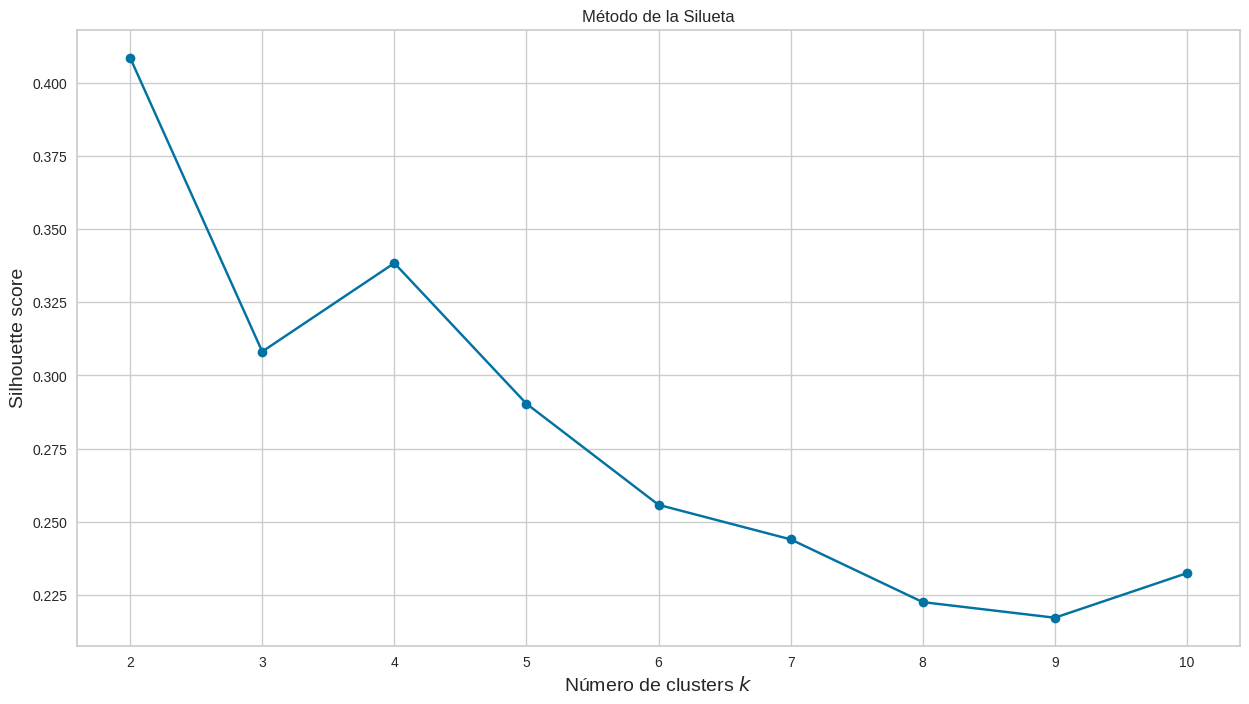

In [ ]:
# generación de los modelos para diferentes valores de $k$
models = [KMeans(n_clusters=n, random_state=0 ).fit(df) for n in range(2,11)]
silhouette_scores = [silhouette_score(df, model.labels_) for model in models]

# gráficamos los valores de la silueta para cada valor de k
plt.plot(list(range(2, 11)), silhouette_scores, "bo-")
plt.xlabel("Número de clusters $k$", fontsize=14)
plt.ylabel("Silhouette score", fontsize=14)
plt.title("Método de la Silueta")
plt.show()

**Silluette Plot**

El Silhouette Plot permite visualizar la calidad del agrupamiento de cada observación. Mientras que el Silhouette Score proporciona un único valor promedio para todo el modelo, este gráfico permite analizar el comportamiento de cada clúster e identificar observaciones que podrían estar asignadas a grupos poco adecuados.

Cada región de color representa un clúster y está formada por los coeficientes de silueta individuales de las observaciones que pertenecen a él.

Interesa observar si los grupos tienen coeficientes positivos, si existen observaciones con valores negativos y si algunos clústeres presentan una calidad de agrupamiento considerablemente menor que otros.

In [ ]:
k = 2                               # número de clusters
kmeans_4 = KMeans(n_clusters=k,         # Definir el modelo
                random_state=0)         # Semilla aleatoria.
kmeans_4.fit(df)                        # Entrenar el modelo

KMeans(n_clusters=2, random_state=0)

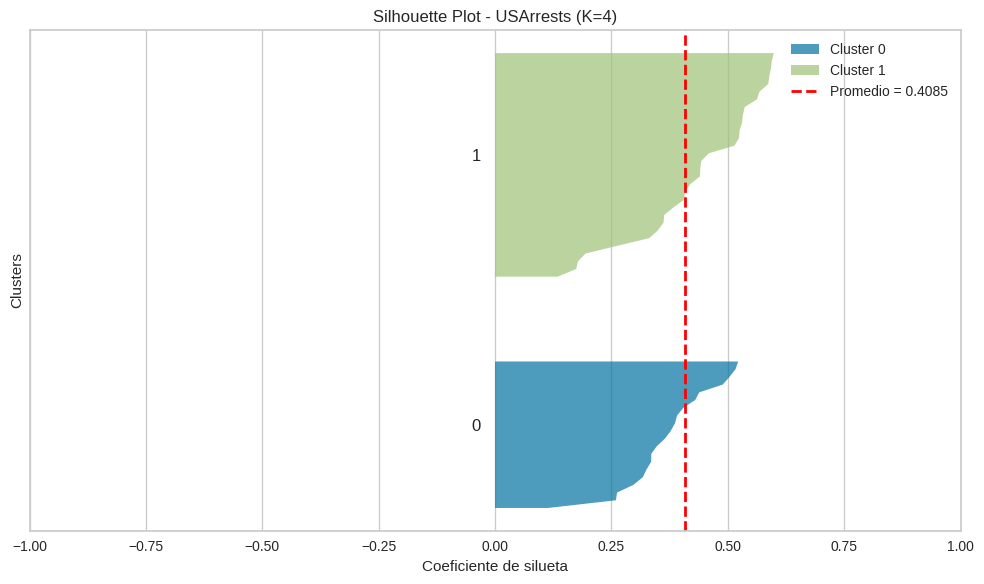

In [ ]:
from sklearn.metrics import silhouette_samples, silhouette_score

# Datos y etiquetas del modelo entrenado
X = df
labels = kmeans_4.labels_

# 1. Silueta promedio
silhouette_avg = silhouette_score(X, labels)

# 2. Silueta individual de cada estado
sample_silhouette_values = silhouette_samples(X, labels)

# Número de clusters
k = len(np.unique(labels))

# 3. Construcción del gráfico
fig, ax = plt.subplots(figsize=(10, 6))

y_lower = 10

for i in range(k):

    # Seleccionar las siluetas del cluster i
    ith_cluster_values = sample_silhouette_values[labels == i]

    # Ordenar los coeficientes
    ith_cluster_values.sort()

    # Cantidad de estados en el cluster
    size_cluster_i = ith_cluster_values.shape[0]

    y_upper = y_lower + size_cluster_i

    # Dibujar cada cluster
    ax.fill_betweenx(
        np.arange(y_lower, y_upper),
        0,
        ith_cluster_values,
        alpha=0.7,
        label=f"Cluster {i}"
    )

    # Identificar el cluster
    ax.text(
        -0.05,
        y_lower + size_cluster_i / 2,
        str(i)
    )

    y_lower = y_upper + 10

# 4. Línea del promedio general
ax.axvline(
    x=silhouette_avg,
    color="red",
    linestyle="--",
    linewidth=2,
    label=f"Promedio = {silhouette_avg:.4f}"
)

# Presentación
ax.set_title("Silhouette Plot - USArrests (K=4)")
ax.set_xlabel("Coeficiente de silueta")
ax.set_ylabel("Clusters")

ax.set_xlim([-1, 1])
ax.set_yticks([])
ax.legend()

plt.tight_layout()
plt.show()


- Clúster 0 (azul): sus observaciones están asignadas a grupos relativamente coherentes según la silueta. Sin embargo, algunos estados tienen coeficientes bajos, lo que indica que su separación respecto a otros grupos es limitada.

- Clúster 1 (verde): también presenta coeficientes positivos. Hay estados relativamente próximos a las fronteras de otros clústeres.

- Clúster 2 (rojo): presenta varios coeficientes superiores al promedio general, aunque también incluye observaciones con valores inferiores a este.

- Clúster 3 (morado): presenta una pequeña región negativa. Esto indica que al menos un estado tiene una distancia promedio menor respecto a otro clúster que respecto al grupo al que fue asignado.

Esto no significa que k-means este mal.

**Índice Davies-Bouldin**

El índice Davies-Bouldin evalúa la calidad de los clústeres considerando su dispersión interna y la distancia entre sus centroides. Compara cada grupo con aquel que presenta la mayor similitud relativa, entendida como una combinación de dispersión y proximidad.
Su expresión general es:

$$DB=\frac{1}{K}\sum_{i=1}^{K}
\max_{j\neq i}
\left(
\frac{S_i+S_j}{M_{ij}}
\right)
$$

Donde $S_i$ representa la dispersión promedio de las observaciones del clúster $i$ respecto a su centroide y $M_{ij}$ representa la distancia entre los centroides de los clústeres $i$ y $j$.

**Cuanto menor sea el índice Davies-Bouldin, mejor será la agrupación según este criterio, ya que indica grupos relativamente compactos y separados.**

In [ ]:

from sklearn.metrics import davies_bouldin_score

# Calcular índice Davies-Bouldin
db_score = davies_bouldin_score(
    df,
    kmeans_4.labels_
)

print(f"Davies-Bouldin (K=4): {db_score:.4f}")


El modelo K-means con cuatro clústeres obtuvo un índice Davies-Bouldin de 1.0129.

Este indicador evalúa la relación entre la dispersión interna de los grupos y la separación de sus centroides.

Se esperan valores cercanos a cero y en ese caso es mejor la separación.



**Índice Calinski-Harabasz**

El índice Calinski-Harabasz, también conocido como criterio de razón de varianzas, evalúa la relación entre la dispersión existente entre los clústeres y la dispersión interna de cada grupo.

$$ CH=\frac{B_K/(K-1)}{W_K/(n-K)} $$

Donde:

- $B_K$: dispersión entre los clústeres.
- $W_K$: dispersión dentro de los clústeres.
- $K$: número de clústeres.
- $n$: número total de observaciones.

A diferencia del índice Davies-Bouldin, un valor mayor del índice Calinski-Harabasz indica una mejor agrupación según este criterio, porque refleja una mayor separación relativa entre los grupos y una menor dispersión interna.

In [ ]:
from sklearn.metrics import calinski_harabasz_score

# Calcular índice Calinski-Harabasz
ch_score = calinski_harabasz_score(df,
                                   kmeans_4.labels_ )

print(f"Calinski-Harabasz (K=4): {ch_score:.4f}")


El modelo K-means con cuatro clústeres obtuvo un índice Calinski-Harabasz de $37.32$.

Esta métrica evalúa la relación entre la dispersión existente entre los grupos y la dispersión interna de cada clúster, considerando los grados de libertad correspondientes.

Los valores elevados indican una estructura de agrupamiento más favorable según este criterio. Sin embargo, dado que no existe un umbral universal de referencia, el resultado debe interpretarse mediante la comparación con otras soluciones (otros valores) de agrupamiento obtenidas sobre los mismos datos.

# <FONT SIZE=5 COLOR="purple"> 5. Ejemplo 2 de k-means </FONT>

Vamos a revisar el siguiente conjunto de dígitos

In [ ]:
from sklearn.datasets import load_digits
from PIL import Image

In [ ]:
digits = load_digits()
data = digits.data

Vamos un elemento de este conjunto

In [ ]:
data[1]

array([ 0.,  0.,  0., 12., 13.,  5.,  0.,  0.,  0.,  0.,  0., 11., 16.,
        9.,  0.,  0.,  0.,  0.,  3., 15., 16.,  6.,  0.,  0.,  0.,  7.,
       15., 16., 16.,  2.,  0.,  0.,  0.,  0.,  1., 16., 16.,  3.,  0.,
        0.,  0.,  0.,  1., 16., 16.,  6.,  0.,  0.,  0.,  0.,  1., 16.,
       16.,  6.,  0.,  0.,  0.,  0.,  0., 11., 16., 10.,  0.,  0.])

Observe que son los valores de colores en escalas de grises. Podemos cambiar la escala

In [ ]:
data = 255-data

In [ ]:
data[1]

array([255., 255., 255., 243., 242., 250., 255., 255., 255., 255., 255.,
       244., 239., 246., 255., 255., 255., 255., 252., 240., 239., 249.,
       255., 255., 255., 248., 240., 239., 239., 253., 255., 255., 255.,
       255., 254., 239., 239., 252., 255., 255., 255., 255., 254., 239.,
       239., 249., 255., 255., 255., 255., 254., 239., 239., 249., 255.,
       255., 255., 255., 255., 244., 239., 245., 255., 255.])

Veamos el elemento gráfico

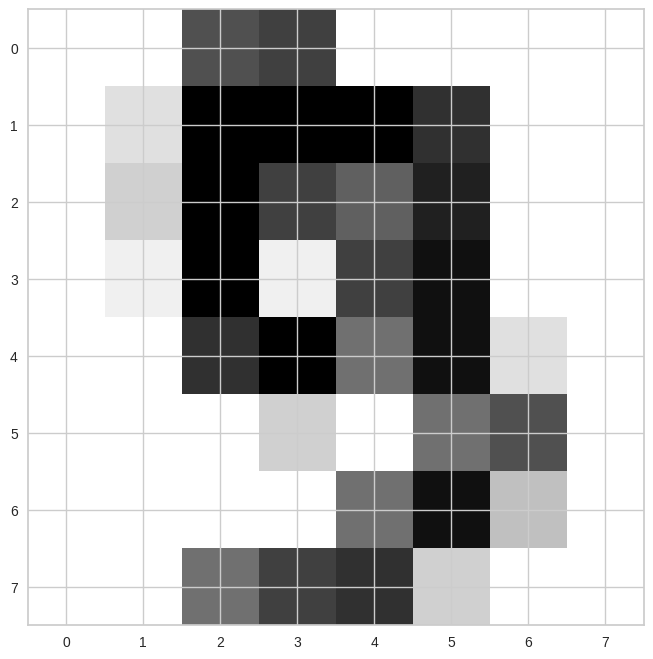

In [ ]:
imagen = data[9, ]
imagen = imagen.reshape(8, 8)
plt.imshow(imagen, cmap=plt.cm.gray)

Veamos más elementos

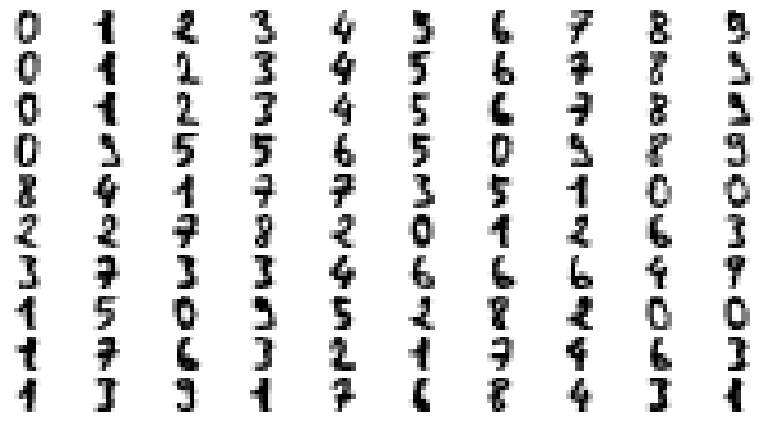

In [ ]:
plt.figure(figsize=(10,10))
for k in range(0, 100):
  plt.subplot(19, 10, k+1)
  imagen = data[k, ]
  imagen = imagen.reshape(8, 8)
  plt.imshow(imagen, cmap=plt.cm.gray)
  plt.axis('off')
plt.show()

In [ ]:
print(data.shape)

(1797, 64)


El objetivo del ejercicio es utilizar *k-means* para agrupar los dígitos.

In [ ]:
# fijamos una semilla
np.random.seed(1)

# Generamos el modelo
kmeans = KMeans(n_clusters=10,
                init='random')
kmeans.fit(data)
predict = kmeans.predict(data)

In [ ]:
# elementos donde se cumple que el clúster es 1
fila = np.where(predict==1)[0]
fila

array([   3,   13,   23,   45,   59,   60,   62,   63,   83,   89,   91,
         92,   98,  133,  143,  153,  161,  175,  189,  190,  192,  193,
        213,  217,  219,  226,  259,  269,  279,  301,  315,  316,  318,
        319,  339,  345,  347,  354,  359,  385,  389,  399,  409,  431,
        445,  469,  475,  477,  484,  489,  561,  576,  614,  619,  649,
        659,  669,  691,  696,  705,  706,  708,  709,  721,  729,  735,
        737,  744,  749,  779,  789,  799,  821,  835,  836,  838,  839,
        859,  865,  867,  874,  879,  908,  918,  928,  947,  950,  961,
        962,  964,  965,  985,  990,  992,  999, 1004, 1032, 1038, 1042,
       1052, 1074, 1086, 1087, 1089, 1090, 1104, 1110, 1116, 1125, 1130,
       1150, 1160, 1170, 1180, 1216, 1217, 1219, 1220, 1240, 1246, 1248,
       1255, 1260, 1290, 1300, 1309, 1310, 1332, 1337, 1338, 1341, 1344,
       1346, 1347, 1349, 1350, 1364, 1370, 1376, 1378, 1385, 1390, 1418,
       1428, 1438, 1460, 1474, 1475, 1477, 1478, 14

In [ ]:
# número de imágenes que clasificó en el clúster 1
num = fila.shape[0]
num

176

cluster 0
182 elementos


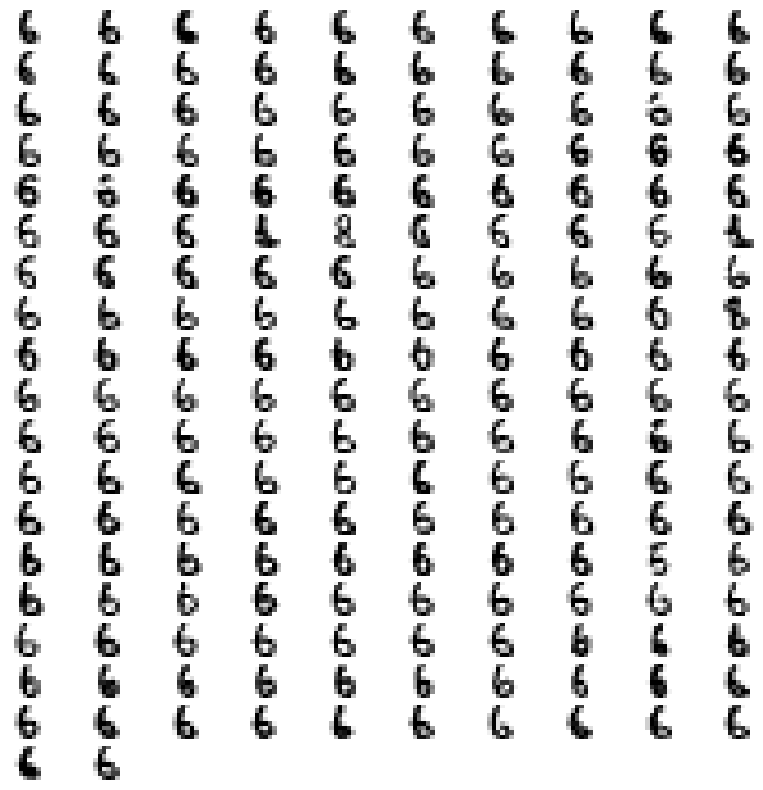

cluster 1
176 elementos


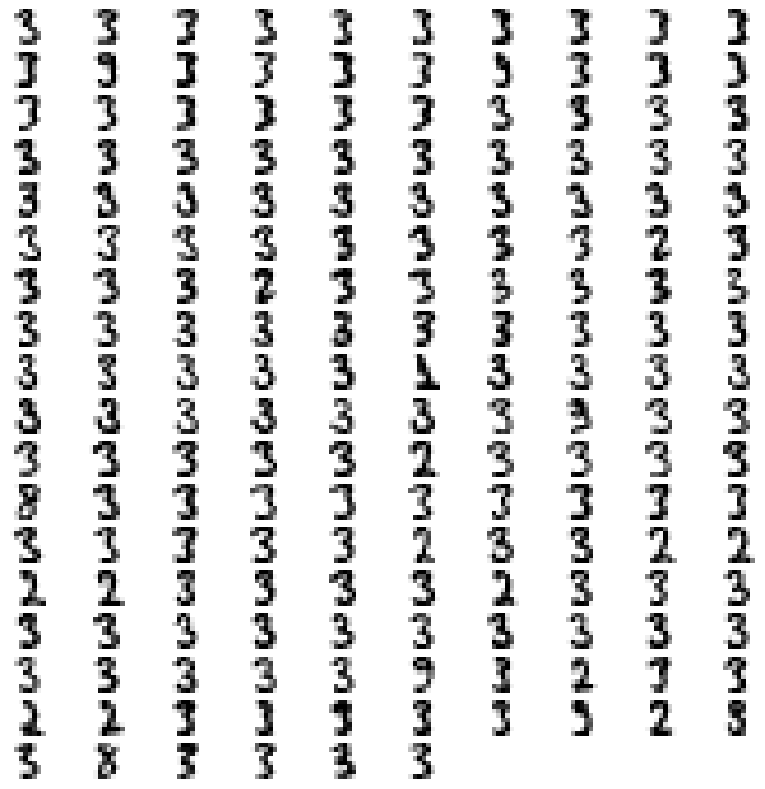

cluster 2
169 elementos


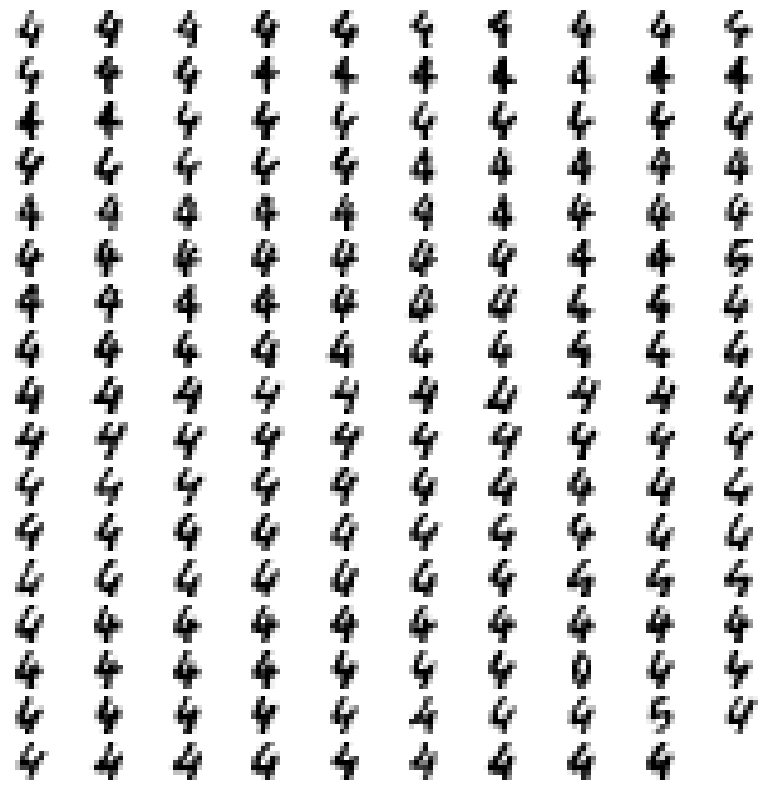

cluster 3
248 elementos


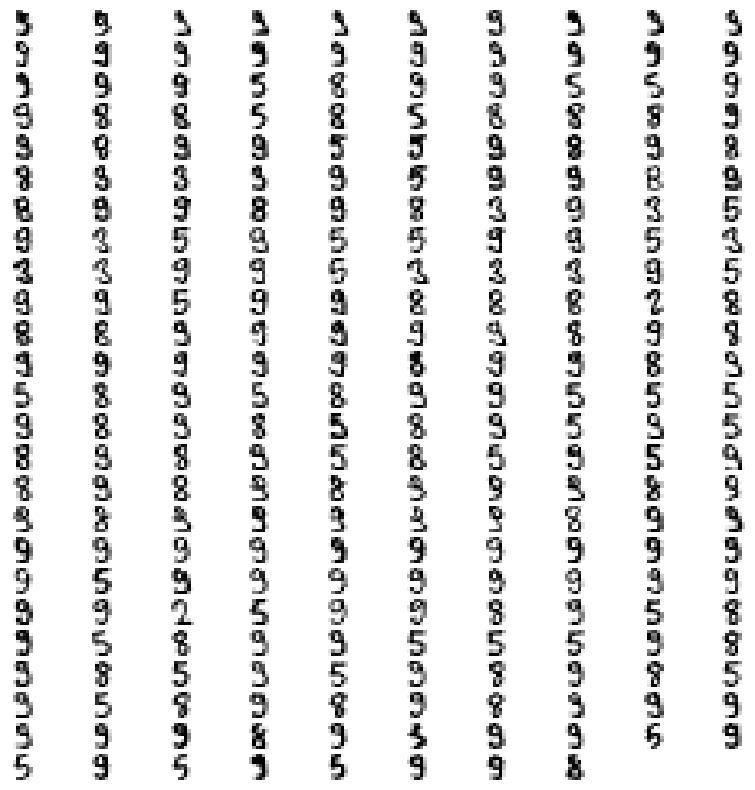

cluster 4
223 elementos


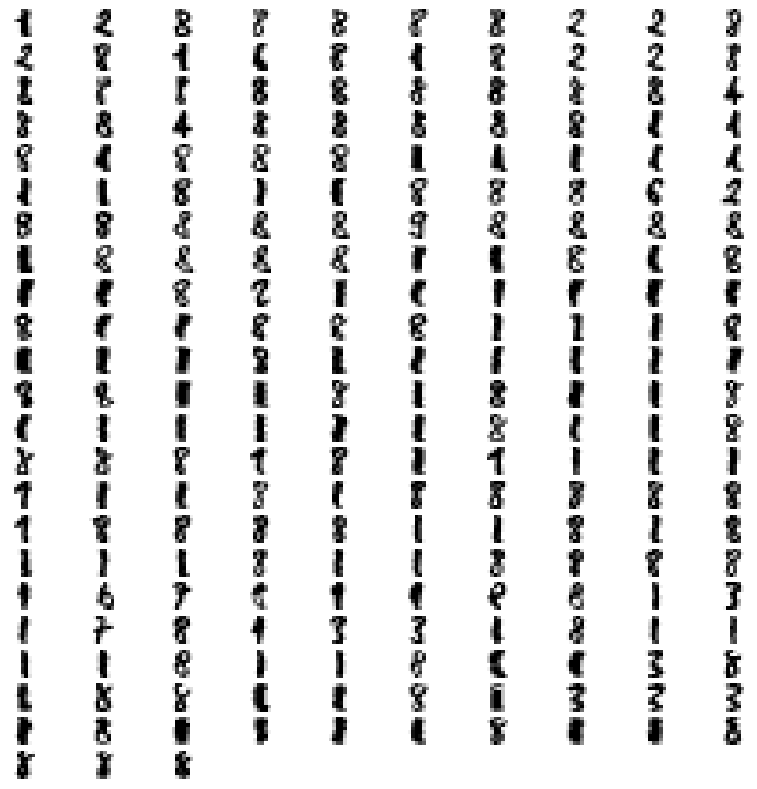

cluster 5
149 elementos


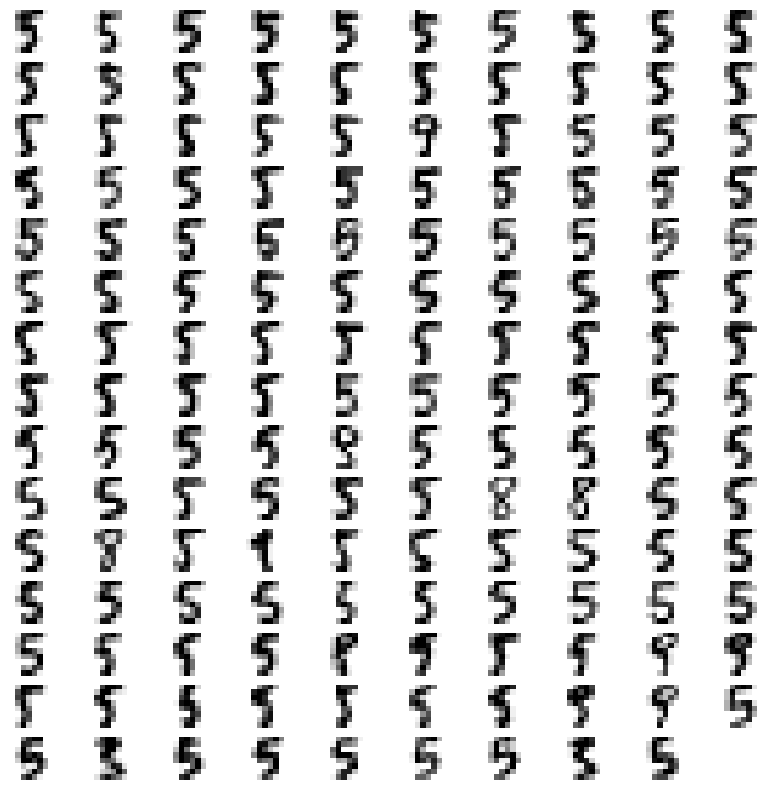

cluster 6
174 elementos


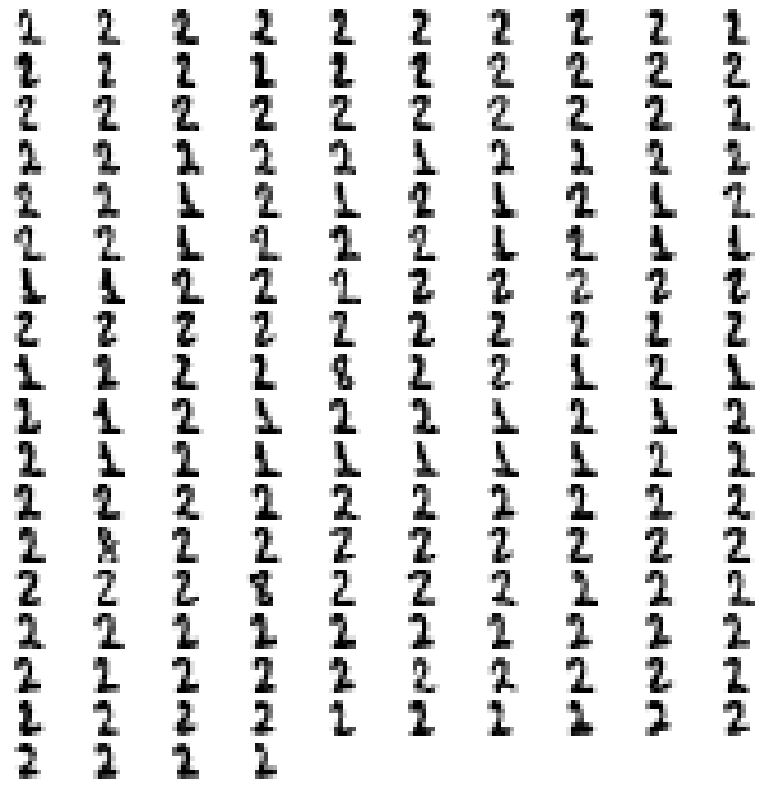

cluster 7
209 elementos


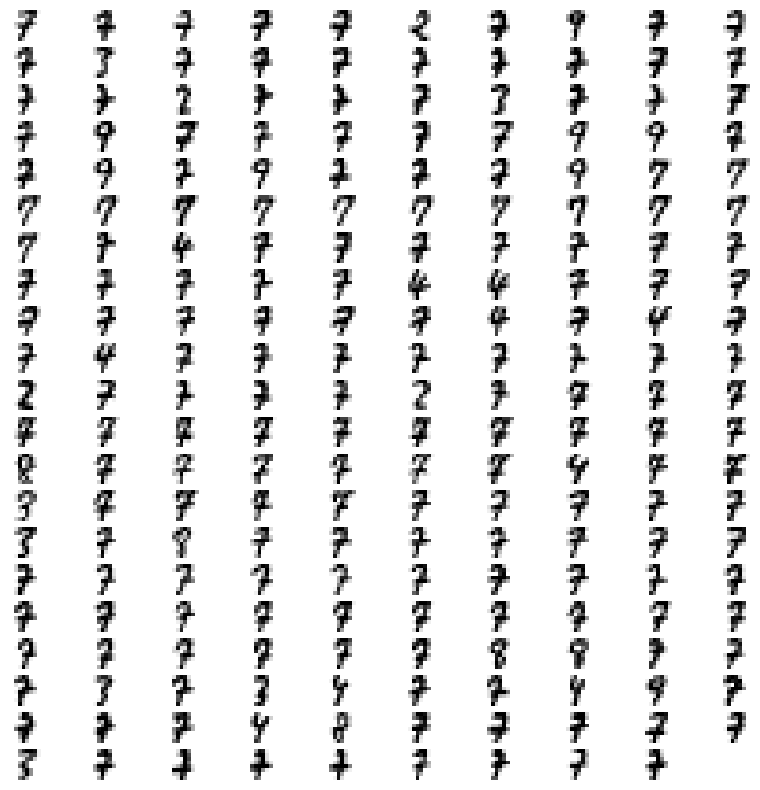

cluster 8
88 elementos


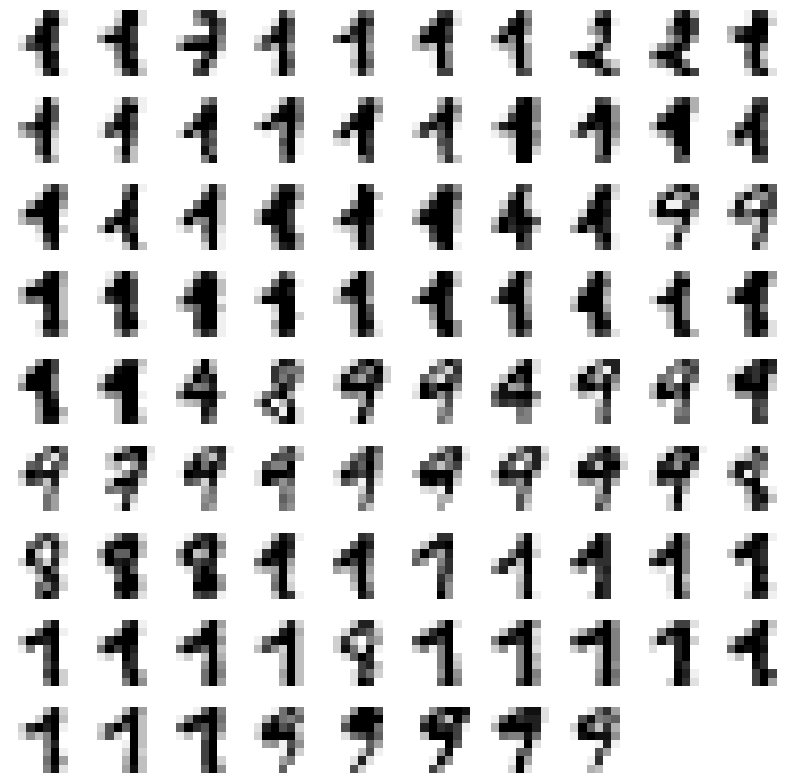

cluster 9
179 elementos


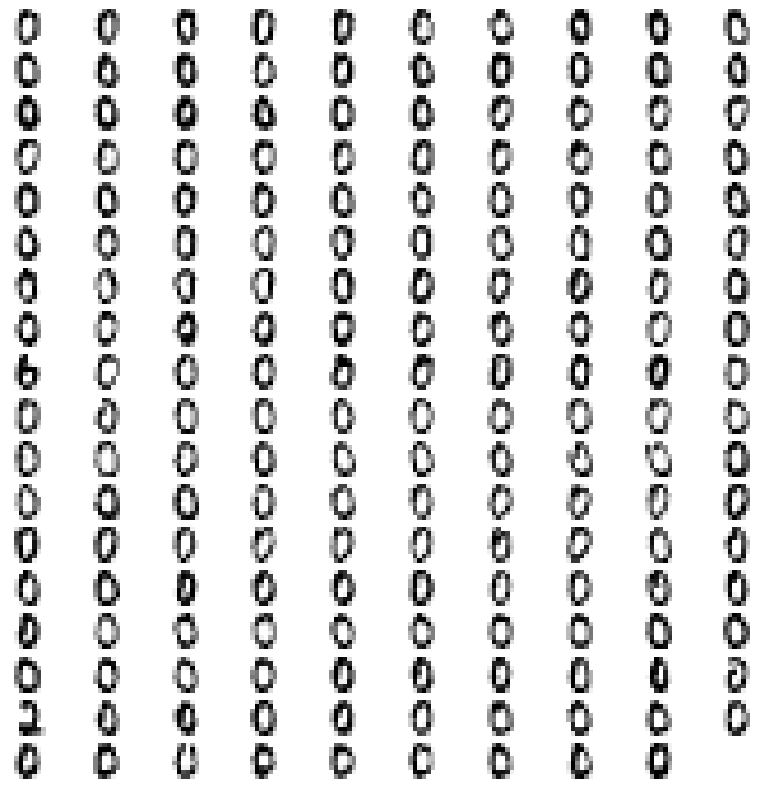

In [ ]:
for i in range(0,10):

    fila = np.where(predict==i)[0]   # filas en predict donde están las imágenes de cada cluster
    num = fila.shape[0]              # número imagenes de cada cluster
    r = np.floor(num/10.)            # número de filas menos 1 en figura de salida

    print("cluster "+str(i))
    print(str(num)+" elementos")

    plt.figure(figsize=(10,10))
    for k in range(0, num):
        plt.subplot(int(r+1), 10, k+1)
        imagen = data[fila[k], ]
        imagen = imagen.reshape(8, 8)
        plt.imshow(imagen, cmap=plt.cm.gray)
        plt.axis('off')
    plt.show()

In [ ]:
%%html
<center><marquee style='width: 60%; color: blue;'><b>Muchas gracias por asistir a la clase</b></marquee><center>